# Initial Test on Quantum Channels

This analysis looks at the DW key rate and the guessing probability for the optimial eve attack where Eve's probe states are under a noisy quantum channel. There are three considered so far. 

In [4]:
from modules import *

import numpy as np
from qutip import tensor
import matplotlib.pyplot as plt
from qutip import basis

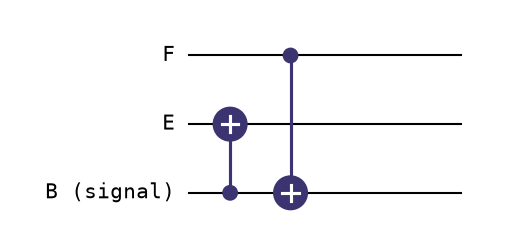

In [5]:
D = 0.10
attack = FGGNPAttack(disturbance=D)
attack.circuit.draw(renderer="matplotlib", wire_label=["B (signal)", "E", "F"])

Apply the attack once for each of the four BB84 inputs. The probability that Bob detects the opposite bit in the same basis should equal $D$ for every input.

In [3]:
zero, one = basis(2, 0), basis(2, 1) # define basis 
bases = {"Z": (zero, one), "X": ((zero + one).unit(), (zero - one).unit())} # define 
probes = {}

for t, inputs in bases.items():
    probes[t] = []
    for bit, psi in enumerate(inputs):
        register = QuantumRegister()
        register.load(psi)
        attack.apply(register)
        wrong = inputs[1 - bit]
        assert np.isclose(register.reduced("B").matrix_element(wrong, wrong), D)
        probes[t].append(register.reduced(attack.probe_labels))

### Noise on each probe

Note that a single-qubit channel acts as,

$$\mathcal N_p(\rho)=\sum_i K_i\rho K_i^\dagger$$

Note the three channels:

- **Depolarizing.** $\mathcal N_p(\rho)=(1-p)\rho+\tfrac p3(X\rho X+Y\rho Y+Z\rho Z)$. With probability $p$, one of the three Pauli errors occurs with equal probability.

- **Phase damping.** $K_0=\mathrm{diag}(1,\sqrt{1-p})$ and $K_1=\sqrt p\,|1\rangle\langle1|$. Populations stay fixed while off-diagonal elements shrink by $\sqrt{1-p}$.

- **Amplitude damping.** The same $K_0$ pairs with $K_1=\sqrt p\,|0\rangle\langle1|$. A probe in $|1\rangle$ relaxes to $|0\rangle$ with probability $p$.

In [3]:
def phase_damping(p):
    return GeneralizedDephasing([zero, np.sqrt(1 - p) * zero + np.sqrt(p) * one]) # rescaling phase damping parameter 

channels = {"Depolarizing": Depolarizing, "Phase damping": phase_damping, "Amplitude damping": AmplitudeDamping}

### Evaluation

Note we evaluate the **guessing probability**, which uses her best joint measurement for that basis. For equally likely bits, the Helstrom formula gives,

$$P_{\rm guess}(t)=\tfrac12+\tfrac14\|\rho_{0,t}-\rho_{1,t}\|_1.$$

The image on the left averages this probability over $Z$ and $X$. For the image on the right we look at the model’s **Devetak–Winter fraction** which is,

$$r=\max\{0,\,1-(\chi_Z+\chi_X)/2-h_2(D)\}.$$

Where the Holevo information is $\chi_t=S((\rho_{0,t}+\rho_{1,t})/2)-[S(\rho_{0,t})+S(\rho_{1,t})]/2$, with $S(\rho)=-\sum_j\lambda_j\log_2\lambda_j$ for eigenvalues $\lambda_j$, and $h_2(D)=-D\log_2 D-(1-D)\log_2(1-D)$ is the cost of correcting Bob’s errors per sifted bit (ideal error correction).

In [4]:
def evaluate(chnnel, p):
    operators = channel(p).kraus_operators()
    joint_ops = [tensor(a, b) for a in operators for b in operators]
    guesses, information = [], []
    for pair in probes.values():
        r0, r1 = [sum(k * rho * k.dag() for k in joint_ops) for rho in pair]
        guesses.append(helstrom_success(r0, r1))
        information.append(holevo_binary(r0.full(), r1.full()))
    key = 1 - np.mean(information) - shannon_entropy([D, 1 - D])
    return np.mean(guesses), max(0, key)

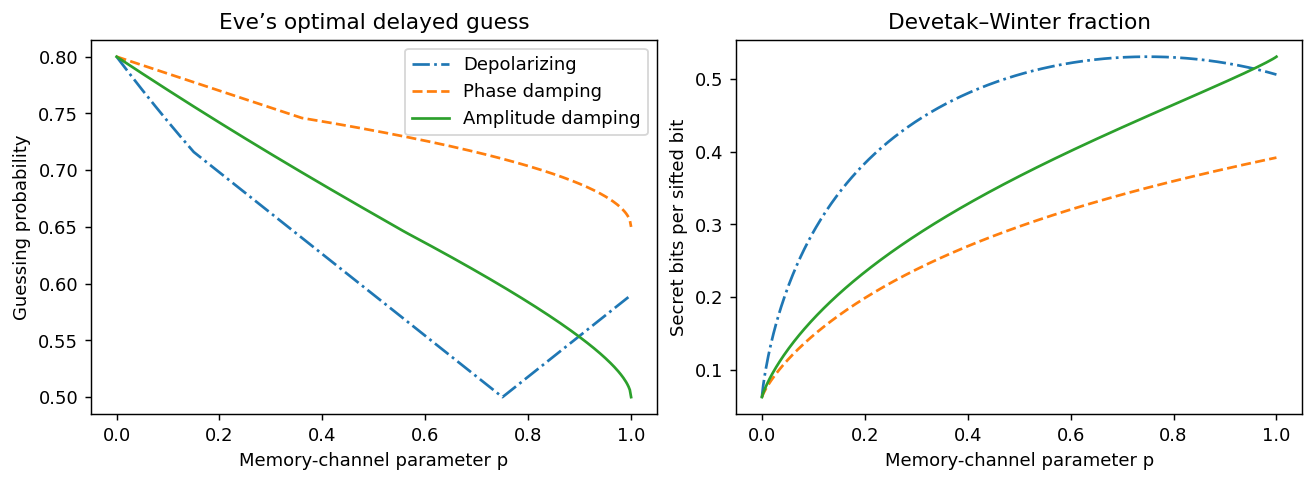

In [5]:
p_values = np.linspace(0, 1, 401)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for (name, channel), style in zip(channels.items(), ["-.", "--", "-"]):
    guesses, rates = np.array([evaluate(channel, p) for p in p_values]).T
    axes[0].plot(p_values, guesses, style, label=name)
    axes[1].plot(p_values, rates, style)

axes[0].set(ylabel="Guessing probability", title="Eve’s optimal delayed guess")
axes[1].set(ylabel="Secret bits per sifted bit", title="Devetak–Winter fraction")
for ax in axes:
    ax.set_xlabel("Memory-channel parameter p")
axes[0].legend()
plt.show()

Realize that in the depolarizing model the depolarizing channel applies $I$ with probability
$1-p$ and each of $X$, $Y$, and $Z$ with probability $p/3$.
At $p=3/4$, all four operations are equally likely because

$$1-p=\frac{p}{3}=\frac14$$

Applying this channel independently to both probes leaves Eve with
the same state, $I_4/4$, whether Alice sent $0$ or $1$. Even after
learning the basis, Eve can only guess at random, so
$P_{\mathrm{guess}}=1/2$.